# 08 · Visualization: what the models learn and where they fail

Bonus task *Visualization*, plus the dense-scene analysis asked for in the Query-based checkpoint.
All analyses use the **fold models and their out-of-fold predictions** (no model sees the frames it is
analysed on), so they describe the same models as the OOF tables.

| section | question |
|---|---|
| 4. W&B | training curves, configurations, OOF metrics and validation predictions with boxes for every Ultralytics experiment |
| 5. Dense scenes | how does AP change with the number of objects per frame, CNN (YOLO) vs query-based (RT-DETR) at the same budget? |
| 6. Grad-CAM (YOLO) | which FPN level explains a detection, and does it depend on object size? |
| 7. Attention (RT-DETR) | where do decoder queries sample (deformable cross-attention), at which feature level, and how does that change across decoder layers? |

Inputs: the notebook outputs that contain `ul_runs/<experiment>` (weights, OOF predictions and per-epoch
history), and the Kaggle secret with the W&B API key (Add-ons → Secrets, attached to this notebook).
GPU optional (sections 6–7 run on a few frames).

## 1. Run configuration

In [1]:
WANDB_SECRET = "viz"                 # label of the Kaggle secret that holds the W&B API key
WANDB_PROJECT = "hw2-ucu-ai-2026"
YOLO_EXP = "yolo_m_1024"             # Grad-CAM model (fold 0); first one found in the inputs is used
YOLO_FALLBACK = ["yolo_1024", "yolo_base"]
RT_EXP = "rtdetr_nq500_960"          # attention model (fold 0)
RT_FALLBACK = ["rtdetr_nq500", "rtdetr_stable"]
PAIRS = [("yolo_base", "rtdetr_stable"),        # same budget: 640 px, 12 epochs, stride 20
         ("yolo_m_1024", "rtdetr_nq500_960")]   # the two final ensemble members
N_VIS_FRAMES = 6                     # validation frames with boxes per experiment (W&B)
N_CAM_FRAMES = 8                     # frames for the Grad-CAM / attention statistics
CONF = 0.3                           # score threshold for the visualised detections

## 2. Setup

In [2]:
import os, sys, shutil, subprocess, time, urllib.request
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"
try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "ultralytics==8.4.203", "pycocotools", "ensemble-boxes"], check=True, timeout=1800)
try:   # faster-coco-eval: drop-in replacement of pycocotools, identical metrics, several times faster
    import faster_coco_eval
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "faster-coco-eval"], timeout=900)
try:
    import faster_coco_eval
    faster_coco_eval.init_as_pycocotools()   # must run before `common` imports pycocotools
except Exception as e:
    print("faster-coco-eval unavailable, using pycocotools:", type(e).__name__)

REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"

def fetch(url, dst, timeout=60, tries=5):
    # download with a timeout and retries: a stalled GitHub request must not hang a commit for hours
    for i in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                Path(dst).write_bytes(r.read())
            return dst
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"{url}: {type(e).__name__}, retry in 30 s"); time.sleep(30)

SRC_FILES = ["common.py", "ul_dataset.py", "splits.json"]
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    # GitHub is the source of truth; an attached copy is only a fallback when GitHub is unreachable
    SRC = Path("/tmp/hw2_src"); SRC.mkdir(exist_ok=True)
    for f in SRC_FILES:
        try:
            fetch(REPO_RAW + f, SRC / f, tries=3); print(f"{f}: GitHub")
        except Exception:
            found = [p for pat in ["*", "*/*", "*/*/*"] for p in sorted(Path("/kaggle/input").glob(f"{pat}/{f}"))
                     if "competitions" not in p.parts] if Path("/kaggle/input").exists() else []
            if not found:
                raise
            shutil.copy(found[0], SRC / f); print(f"{f}: {found[0]} (GitHub unreachable)")
sys.path.insert(0, str(SRC))

common.py: GitHub
ul_dataset.py: GitHub
splits.json: GitHub


In [3]:
import importlib, json
import cv2
import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
from IPython.display import display

import common, ul_dataset as uld
importlib.reload(common); importlib.reload(uld)

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / "ul_runs_in"       # restored from the attached outputs (not part of this output)
IMG_DIR = WORK / "images"
for p in (RUN_ROOT, IMG_DIR):
    p.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
uld.restore_from_inputs(RUN_ROOT)
EXPS = sorted(p.parent.name for p in RUN_ROOT.glob("*/config.json"))
print("device:", DEVICE, "| experiments found:", EXPS)
names = list(common.CLASSES)

restored 52 finished folds from /kaggle/input
device: cuda | experiments found: ['rtdetr_base', 'rtdetr_nq500', 'rtdetr_nq500_960', 'rtdetr_nq500_960_s10', 'rtdetr_nq500_giou', 'rtdetr_nq500_nodn', 'rtdetr_stable', 'yolo_1024', 'yolo_1024_e24', 'yolo_1024_nop5', 'yolo_1024_p2', 'yolo_1024_p2_e24', 'yolo_1024_p2_nop5', 'yolo_832', 'yolo_base', 'yolo_m_1024', 'yolo_nwd', 'yolo_p2']


### W&B login
The key is read from the Kaggle secret; without it the runs are written offline (`wandb/` folder)
so the notebook still runs end to end.

In [4]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], timeout=600)
import wandb
try:
    from kaggle_secrets import UserSecretsClient
    wandb.login(key=UserSecretsClient().get_secret(WANDB_SECRET), relogin=True)
    WANDB_MODE = "online"
except Exception as e:
    print("no W&B key (", type(e).__name__, "): logging offline")
    WANDB_MODE = "offline"

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: onopriienko-pn (onopriienko-pn-) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 3. Results table
Latest OOF row of every experiment (both team members) from the repo `results.csv`, falling back to the
`results.csv` files of the attached outputs.

In [5]:
try:
    fetch(REPO_RAW + "results.csv", "/tmp/results_repo.csv", tries=3)
    res = pd.read_csv("/tmp/results_repo.csv")
except Exception:
    res = pd.concat([pd.read_csv(f) for f in uld._input_files("/kaggle/input", "results.csv")], ignore_index=True)
oof = (res[res["fold"].astype(str) == "oof"].sort_values("timestamp").drop_duplicates("experiment", keep="last")
       .set_index("experiment"))
COLS = ["owner", "model", "imgsz", "epochs", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "fps", "public_lb"]
display(oof[[c for c in COLS if c in oof]].sort_values("mAP", ascending=False))

,owner,model,imgsz,epochs,mAP,AP50,AP_small,AP_medium,AP_large,fps,public_lb
experiment,,,,,,,,,,,
yolo_1024,B,yolo,1024,12,0.1892,0.3646,0.0617,0.1644,0.3498,48.51,NaN
rtdetr_stable,B,rtdetr,640,12,0.1825,0.3528,0.0611,0.1541,0.3482,18.03,NaN
yolo_base,B,yolo,640,12,0.1233,0.2519,0.0367,0.1085,0.2740,53.60,NaN
yolo_nwd,B,yolo,640,12,0.1199,0.2450,0.0372,0.1055,0.2682,51.13,NaN
frcnn_anch05,A,faster_rcnn,640,12,0.1158,0.2637,0.0344,0.1023,0.2368,23.20,NaN
frcnn_base,A,faster_rcnn,640,12,0.1131,0.2501,0.0307,0.0929,0.2446,24.60,NaN
yolo_p2,B,yolo,640,12,0.0868,0.1955,0.0284,0.0890,0.1706,48.96,NaN
retina_g1,A,retinanet,640,12,0.0831,0.1988,0.0187,0.0739,0.1961,22.50,NaN
retina_anch05,A,retinanet,640,12,0.0798,0.1910,0.0181,0.0709,0.1913,22.20,NaN


## 4. Weights & Biases
One W&B run per experiment: its configuration (`config.json`), the per-epoch training and validation
curves of every fold (Ultralytics history, `fold<k>/...`), the OOF metrics as summary, and
`N_VIS_FRAMES` validation frames of fold 0 with ground truth and OOF predictions as bounding boxes.
Experiments of the torchvision part (owner A) get a run with their configuration-free summary only.

In [6]:
def load_frame(path, max_side=960):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), s

def wb_boxes(df, s, scores=False):
    out = []
    for r in df.itertuples():
        b = {"position": {"minX": r.x * s, "minY": r.y * s, "maxX": (r.x + r.w) * s, "maxY": (r.y + r.h) * s},
             "domain": "pixel", "class_id": int(r.cls), "box_caption": names[int(r.cls)]}
        if scores:
            b["scores"] = {"score": float(r.score)}
            b["box_caption"] += f" {r.score:.2f}"
        out.append(b)
    return out

LABELS = {i: n for i, n in enumerate(names)}
VIS = common.fold_images(images, splits, 0, "val", common.EVAL_STRIDE)
VIS = VIS.iloc[np.linspace(0, len(VIS) - 1, N_VIS_FRAMES).astype(int)]
GT = anns[anns["iscrowd"] == 0]

In [7]:
logged = WORK / "wandb_logged"
if not logged.exists() and not uld._input_files("/kaggle/input", "wandb_logged"):   # an earlier version already logged
    for exp in EXPS:
        cfg = json.loads((RUN_ROOT / exp / "config.json").read_text())
        run = wandb.init(project=WANDB_PROJECT, name=exp, config=cfg, group=cfg.get("model"), mode=WANDB_MODE,
                         job_type="experiment", reinit="finish_previous")
        done = uld.load_done(RUN_ROOT, exp)
        for k, d in done.items():
            for h in d.get("history", []):
                run.log({f"fold{k}/{m}": v for m, v in h.items() if m != "epoch"} | {"epoch": h["epoch"]})
        if exp in oof.index:
            run.summary.update({f"oof/{m}": float(oof.at[exp, m]) for m in ["mAP", "AP50", "AP75", "AP_small",
                                "AP_medium", "AP_large", "AR500", "fps"] if pd.notna(oof.at[exp, m])})
        preds = uld.load_fold_preds(RUN_ROOT, exp).get(0)
        if preds is not None:
            imgs = []
            for r in VIS.itertuples():
                img, s = load_frame(r.path)
                p = preds[(preds["img_id"] == r.img_id) & (preds["score"] >= CONF)]
                g = GT[GT["img_id"] == r.img_id]
                imgs.append(wandb.Image(img, caption=f"{r.clip} frame {r.frame_id}: {len(g)} GT, {len(p)} pred >= {CONF}",
                                        boxes={"ground_truth": {"box_data": wb_boxes(g, s), "class_labels": LABELS},
                                               "predictions": {"box_data": wb_boxes(p, s, True),
                                                               "class_labels": LABELS}}))
            run.log({"val_predictions_fold0": imgs})
        run.finish()
    for exp in oof.index[oof["owner"] != "B"]:   # torchvision models: summary only
        run = wandb.init(project=WANDB_PROJECT, name=exp, group=str(oof.at[exp, "model"]), mode=WANDB_MODE,
                         job_type="experiment", reinit="finish_previous",
                         config={c: oof.at[exp, c] for c in ["owner", "model", "imgsz", "epochs", "notes"] if c in oof})
        run.summary.update({f"oof/{m}": float(oof.at[exp, m]) for m in ["mAP", "AP50", "AP_small", "fps"]
                            if pd.notna(oof.at[exp, m])})
        run.finish()
    run = wandb.init(project=WANDB_PROJECT, name="results_table", job_type="summary", mode=WANDB_MODE,
                     reinit="finish_previous")
    run.log({"oof_results": wandb.Table(dataframe=oof[[c for c in COLS if c in oof]].reset_index())})
    print("W&B project:", run.url.rsplit("/runs/", 1)[0] if run.url else "(offline)")
    run.finish()
    logged.touch()

## 5. Dense scenes: AP vs number of objects per frame
OOF frames (every 10th frame of each fold's validation clips) are split into bins by the number of
annotated objects; every bin is evaluated with the same `common.evaluate` as the main tables. Pairs:
the same budget at 640 px, and the two final ensemble members.

bin,< 30,30–60,60–100,≥ 100
frames,937,1193,384,220


,< 30,30–60,60–100,≥ 100
yolo_base,0.1333,0.1225,0.1333,0.1204
rtdetr_stable,0.1820,0.1874,0.1874,0.1820
yolo_m_1024,0.2222,0.1928,0.2243,0.2164
rtdetr_nq500_960,0.2314,0.2263,0.2405,0.2332


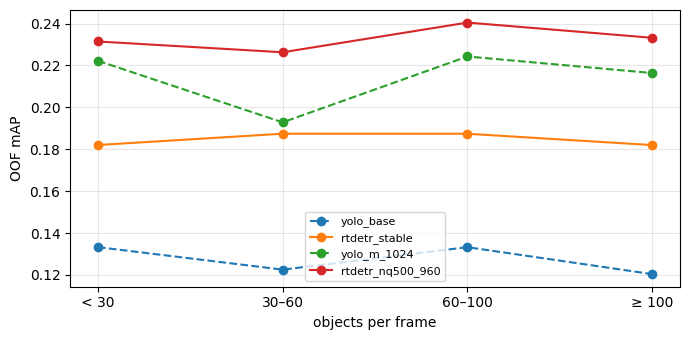

In [8]:
ev = pd.concat([common.fold_images(images, splits, k, "val", common.EVAL_STRIDE) for k in range(common.N_FOLDS)])
n_obj = GT.groupby("img_id").size().reindex(ev["img_id"]).fillna(0).to_numpy()
BINS = [0, 30, 60, 100, 10_000]
LAB = ["< 30", "30–60", "60–100", "≥ 100"]
ev = ev.assign(n_obj=n_obj, bin=pd.cut(n_obj, BINS, right=False, labels=LAB))
display(ev["bin"].value_counts().reindex(LAB).rename("frames").to_frame().T)

dens = {}
for pair in PAIRS:
    for exp in pair:
        fp = uld.load_fold_preds(RUN_ROOT, exp)
        if len(fp) < common.N_FOLDS or exp in dens:
            continue
        p = pd.concat(fp.values(), ignore_index=True)
        dens[exp] = {b: common.evaluate(p, images, anns, ev.loc[ev["bin"] == b, "img_id"])["mAP"] for b in LAB}
dens = pd.DataFrame(dens).T[LAB]
display(dens.round(4))
fig, ax = plt.subplots(figsize=(7, 3.5))
for exp, row in dens.iterrows():
    ax.plot(LAB, row.values, marker="o", ls="--" if "rtdetr" not in exp else "-", label=exp)
ax.set_xlabel("objects per frame"); ax.set_ylabel("OOF mAP"); ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(IMG_DIR / "08_density.png"); plt.show()

**Observations (dense scenes):** RT-DETR is almost insensitive to scene density: `rtdetr_stable` stays within 0.182–0.187 across all bins and `rtdetr_nq500_960` within 0.226–0.241. YOLO varies more (`yolo_m_1024` 0.193–0.224), and at the same 640 px budget RT-DETR beats YOLO in every bin (by 37–53%). Very dense frames (≥ 100 objects) are not the worst for any model, so density alone does not make a frame hard. Both YOLO models dip at 30–60 objects while RT-DETR does not, so YOLO is more sensitive to whatever makes those scenes harder (e.g. smaller objects at higher altitude).

## 6. Grad-CAM on the feature levels of YOLO
For a detection (anchor *a*, class *c*) the target is its class score; Grad-CAM (Selvaraju et al. 2017)
weights each channel of a feature map by its average gradient and keeps the positive part.

Which maps: the three backbone stages that feed the FPN (C3 / C4 / C5 = layers 4 / 6 / 9, strides
8 / 16 / 32). A detection from the P3 head depends on all three through the top-down path, so the
share of Grad-CAM energy per stage shows which resolution explains it. (The neck outputs P3/P4/P5 are
not used: a P3 detection does not depend on the later P4/P5 outputs at all, so their CAM is zero by
construction.) The level of the anchor that produced the detection is reported as well. Implemented with
forward hooks (idea of `pytorch-grad-cam`, code written for the Ultralytics Detect output).

In [9]:
def first_found(exp, fallback):
    for e in [exp] + fallback:
        if (RUN_ROOT / e / "fold0" / "final.pt").exists():
            return e
    return None

def letterbox(img, size):
    r = size / max(img.shape[:2])
    im = cv2.resize(img, (round(img.shape[1] * r), round(img.shape[0] * r)), interpolation=cv2.INTER_LINEAR)
    out = np.full((size, size, 3), 114, np.uint8); out[:im.shape[0], :im.shape[1]] = im
    return out, r

def to_tensor(img):
    return torch.from_numpy(img).permute(2, 0, 1)[None].float().div(255).to(DEVICE)

CAM_FRAMES = common.fold_images(images, splits, 0, "val", common.EVAL_STRIDE)   # fold 0 model -> fold 0 val frames
CAM_FRAMES = CAM_FRAMES.iloc[np.linspace(0, len(CAM_FRAMES) - 1, N_CAM_FRAMES).astype(int)]
YEXP = first_found(YOLO_EXP, YOLO_FALLBACK)
ycfg = json.loads((RUN_ROOT / YEXP / "config.json").read_text())
ymodel = uld.load_trained(uld.Config(model="yolo"), RUN_ROOT / YEXP / "fold0" / "final.pt").model.float().to(DEVICE).eval()
det = ymodel.model[-1]
HEADS = list(det.f)                  # Detect inputs (P3, P4, P5)
LEVELS = [4, 6, 9]                   # backbone stages C3, C4, C5 (indices of yolov8.yaml, kept in our custom heads)
print("Grad-CAM model:", YEXP, "| backbone stages:", LEVELS, "| Detect inputs:", HEADS, "| strides:", det.stride.tolist())

Grad-CAM model: yolo_m_1024 | backbone stages: [4, 6, 9] | Detect inputs: [15, 18, 21] | strides: [8.0, 16.0, 32.0]


In [10]:
acts = {}
hooks = [ymodel.model[i].register_forward_hook(lambda m, inp, out, i=i: acts.__setitem__(i, out)) for i in LEVELS + HEADS]

def yolo_cams(img_rgb, size):
    x, r = letterbox(img_rgb, size)
    out = ymodel(to_tensor(x).requires_grad_(True))
    out = out[0] if isinstance(out, (tuple, list)) else out          # (1, 4 + nc, anchors)
    boxes, scores = out[0, :4].T, out[0, 4:].T                        # xywh (letterbox px), sigmoid scores
    conf, cls = scores.max(1)
    keep = torch.where(conf >= CONF)[0]
    xyxy = torch.cat([boxes[:, :2] - boxes[:, 2:] / 2, boxes[:, :2] + boxes[:, 2:] / 2], 1)
    keep = keep[torchvision.ops.batched_nms(xyxy[keep].detach(), conf[keep].detach(), cls[keep], 0.6)]
    hw = [acts[i].shape[-2:] for i in HEADS]
    level_of = np.repeat(np.arange(len(HEADS)), [h * w for h, w in hw])
    rows = []
    for a in keep.tolist():
        g = torch.autograd.grad(scores[a, cls[a]], [acts[i] for i in LEVELS], retain_graph=True)
        cams = [torch.relu((gi.mean((2, 3), keepdim=True) * acts[i]).sum(1))[0].detach() for gi, i in zip(g, LEVELS)]
        energy = np.array([c.sum().item() for c in cams])
        rows.append(dict(anchor=a, level=int(level_of[a]), cls=int(cls[a]), conf=conf[a].item(),
                         size=float(boxes[a, 2:].detach().prod().sqrt() / r), box=xyxy[a].detach().cpu().numpy(),
                         share=energy / max(energy.sum(), 1e-12), cams=[c.cpu().numpy() for c in cams]))
    return x, rows

stats, examples = [], []
for f in CAM_FRAMES.itertuples():
    img = cv2.cvtColor(cv2.imread(str(f.path)), cv2.COLOR_BGR2RGB)
    x, rows = yolo_cams(img, ycfg["imgsz"])
    stats += [{k: v for k, v in r.items() if k not in ("cams", "box")} for r in rows]
    if rows and len(examples) < 2:
        examples.append((x, min(rows, key=lambda r: r["size"]), max(rows, key=lambda r: r["size"])))
for h in hooks:
    h.remove()
cam = pd.DataFrame(stats)
cam["size_bin"] = pd.cut(cam["size"], [0, 16, 32, 64, 1e4], labels=["< 16 px", "16–32", "32–64", "≥ 64"])
lv = [f"C{3 + i}" for i in range(len(LEVELS))]
hv = [f"P{3 + i}" for i in range(len(HEADS))]
share = pd.DataFrame(cam["share"].tolist(), columns=lv).groupby(cam["size_bin"].values, observed=True).mean()
own = pd.crosstab(cam["size_bin"], cam["level"].map(dict(enumerate(hv))), normalize="index")
print(f"{len(cam)} detections (score >= {CONF}) on {len(CAM_FRAMES)} frames")
print("Grad-CAM energy share per backbone stage (mean over detections):"); display(share.round(3))
print("head level of the anchor that produced the detection:"); display(own.round(3))

412 detections (score >= 0.3) on 8 frames
Grad-CAM energy share per backbone stage (mean over detections):


,C3,C4,C5
< 16 px,0.563,0.307,0.130
16–32,0.482,0.379,0.139
32–64,0.424,0.390,0.186
≥ 64,0.395,0.415,0.190


head level of the anchor that produced the detection:


level,P3,P4
size_bin,,
< 16 px,1.000,0.000
16–32,0.947,0.053
32–64,0.846,0.154
≥ 64,0.473,0.527


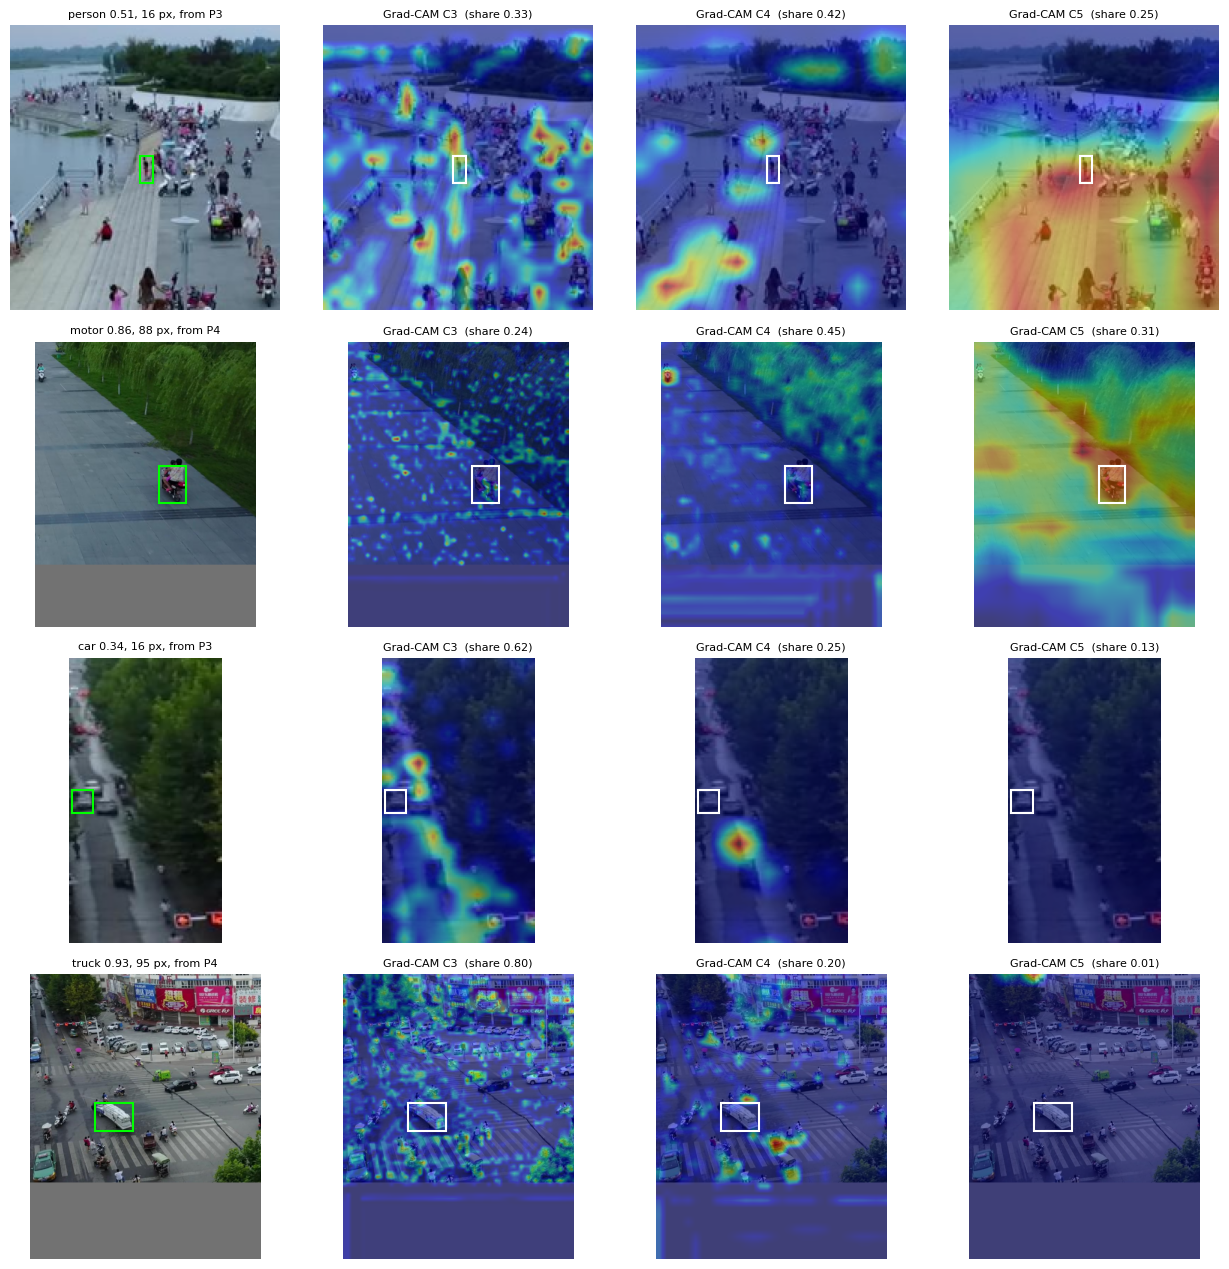

In [11]:
def overlay(ax, img, cam_map, box=None, title=""):
    m = cv2.resize(cam_map / (cam_map.max() + 1e-12), (img.shape[1], img.shape[0]))
    ax.imshow(img); ax.imshow(m, cmap="jet", alpha=0.45)
    if box is not None:
        ax.add_patch(plt.Rectangle(box[:2], *(box[2:] - box[:2]), fill=False, ec="w", lw=1.5))
    ax.set_title(title, fontsize=8); ax.axis("off")

if examples:
    fig, axes = plt.subplots(2 * len(examples), len(LEVELS) + 1, figsize=(3.2 * (len(LEVELS) + 1), 3.2 * 2 * len(examples)))
    for e, (x, small, large) in enumerate(examples):
        for j, d in enumerate([small, large]):
            row = axes[2 * e + j]
            b = d["box"]; pad = max(b[2] - b[0], b[3] - b[1]) * 3 + 32
            x0, y0 = int(max(b[0] - pad, 0)), int(max(b[1] - pad, 0))
            x1, y1 = int(min(b[2] + pad, x.shape[1])), int(min(b[3] + pad, x.shape[0]))
            crop = x[y0:y1, x0:x1]
            row[0].imshow(crop); row[0].add_patch(plt.Rectangle((b[0] - x0, b[1] - y0), b[2] - b[0], b[3] - b[1],
                                                                fill=False, ec="lime", lw=1.5))
            row[0].set_title(f"{names[d['cls']]} {d['conf']:.2f}, {d['size']:.0f} px, from {hv[d['level']]}", fontsize=8)
            row[0].axis("off")
            for k, cm in enumerate(d["cams"]):
                full = cv2.resize(cm, (x.shape[1], x.shape[0]))[y0:y1, x0:x1]
                overlay(row[k + 1], crop, full, np.array([b[0] - x0, b[1] - y0, b[2] - x0, b[3] - y0]),
                        f"Grad-CAM {lv[k]}  (share {d['share'][k]:.2f})")
    fig.tight_layout(); fig.savefig(IMG_DIR / "08_gradcam.png", dpi=110); plt.show()

**Observations (Grad-CAM):** Small objects are explained by high-resolution features: for objects < 16 px the stride-8 backbone stage C3 holds 56% of the Grad-CAM energy and the coarse C5 only 13%, while for objects ≥ 64 px C3 drops to 40% and C4/C5 grow. All objects < 16 px are detected by the P3 head and half of the large ones by P4, as the label assignment intends. In the example maps C3 highlights many small objects across the frame, while C5 is a broad low-resolution blob: the coarse level contributes context rather than the object itself.

## 7. RT-DETR: deformable cross-attention of the decoder queries
RT-DETR's decoder uses multi-scale deformable attention (Zhu et al. 2021): each query samples a few
points per head on each of the 3 encoder levels (strides 8 / 16 / 32) and mixes them with learned
weights. These sampling locations and weights are the model's cross-attention; they are recorded by
wrapping `multi_scale_deformable_attn_pytorch` for one forward pass. For the kept queries (score ≥ `CONF`)
we look at (a) which level the attention weight goes to as a function of object size, (b) how far the
sampling points spread around the predicted box in each decoder layer, (c) the points of a few queries.

In [12]:
import ultralytics.nn.modules.transformer as TR
RTEXP = first_found(RT_EXP, RT_FALLBACK)
rcfg = json.loads((RUN_ROOT / RTEXP / "config.json").read_text())
rmodel = uld.load_trained(uld.Config(model="rtdetr"), RUN_ROOT / RTEXP / "fold0" / "final.pt").model.float().to(DEVICE).eval()
NP = rmodel.model[-1].decoder.layers[0].cross_attn.n_points
REC, _orig = [], TR.multi_scale_deformable_attn_pytorch

def _record(value, shapes, loc, w):
    REC.append((loc.detach().cpu(), w.detach().cpu()))
    return _orig(value, shapes, loc, w)

# The decoder's postprocess re-sorts (query, class) pairs by score, so its output rows are not queries.
# Its inputs (boxes and sigmoid scores per query, in query order) are captured instead.
DEC, CAP = rmodel.model[-1], {}
_pp = DEC.postprocess
DEC.postprocess = lambda b, s: (CAP.update(b=b.detach(), s=s.detach()), _pp(b, s))[1]

def rt_attention(img_rgb, size):
    x, r = letterbox(img_rgb, size)
    REC.clear(); TR.multi_scale_deformable_attn_pytorch = _record
    try:
        with torch.no_grad():
            rmodel(to_tensor(x))
    finally:
        TR.multi_scale_deformable_attn_pytorch = _orig
    boxes, scores = CAP["b"][0].cpu(), CAP["s"][0].cpu()             # (queries, 4) cxcywh in [0, 1]; (queries, nc)
    conf, cls = scores.max(1)
    q = torch.where(conf >= CONF)[0]
    return x, r, boxes[q] * size, conf[q], cls[q], q, list(REC)

rows, ex = [], None
for f in CAM_FRAMES.itertuples():
    img = cv2.cvtColor(cv2.imread(str(f.path)), cv2.COLOR_BGR2RGB)
    x, r, boxes, conf, cls, q, rec = rt_attention(img, rcfg["imgsz"])
    if ex is None and len(q) >= 3:
        ex = (x, boxes, conf, cls, q, rec)
    nl = rec[-1][1].shape[-1] // NP
    for j, qi in enumerate(q.tolist()):
        w = rec[-1][1][0, qi]                                         # last layer: (heads, levels * points)
        lvl = w.view(w.shape[0], nl, NP).sum(-1).mean(0).numpy()      # weight per level, mean over heads
        bw, bh = boxes[j, 2:].clamp(min=1).tolist()
        spread = []
        for loc, _ in rec:                                            # every decoder layer
            p = loc[0, qi].reshape(-1, 2) * x.shape[0]                # sampling points (letterbox px)
            d = (p - boxes[j, :2]).abs() / torch.tensor([bw, bh])
            spread.append(float(d.median()))
        rows.append(dict(size=float(np.sqrt(bw * bh) / r), conf=float(conf[j]), **{f"w_P{3 + i}": lvl[i] for i in range(nl)},
                         **{f"spread_L{i + 1}": s for i, s in enumerate(spread)}))
att = pd.DataFrame(rows)
att["size_bin"] = pd.cut(att["size"], [0, 16, 32, 64, 1e4], labels=["< 16 px", "16–32", "32–64", "≥ 64"])
print(RTEXP, f": {len(att)} queries with score >= {CONF} on {len(CAM_FRAMES)} frames")
wcols = [c for c in att if c.startswith("w_P")]; scols = [c for c in att if c.startswith("spread_")]
print("attention weight per level (last decoder layer):"); display(att.groupby("size_bin", observed=True)[wcols].mean().round(3))
print("median |sampling point - box centre| / box size, per decoder layer:")
display(att.groupby("size_bin", observed=True)[scols].median().round(2))

rtdetr_nq500_960 : 581 queries with score >= 0.3 on 8 frames
attention weight per level (last decoder layer):


,w_P3,w_P4,w_P5
size_bin,,,
< 16 px,0.467,0.414,0.119
16–32,0.470,0.399,0.130
32–64,0.461,0.392,0.147
≥ 64,0.404,0.413,0.183


median |sampling point - box centre| / box size, per decoder layer:


,spread_L1,spread_L2,spread_L3,spread_L4,spread_L5,spread_L6
size_bin,,,,,,
< 16 px,0.20,0.19,0.20,0.21,0.21,0.20
16–32,0.19,0.19,0.20,0.22,0.21,0.21
32–64,0.20,0.19,0.22,0.22,0.22,0.21
≥ 64,0.20,0.20,0.24,0.23,0.23,0.22


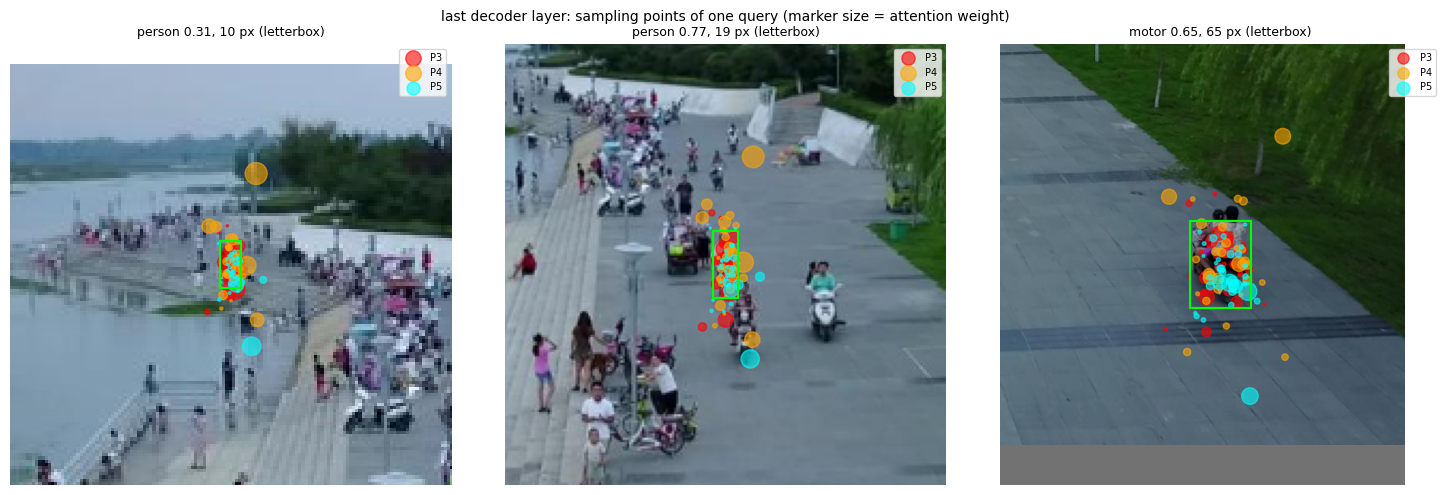

In [13]:
if ex is not None:
    x, boxes, conf, cls, q, rec = ex
    order = boxes[:, 2:].prod(1).argsort()
    pick = [order[0].item(), order[len(order) // 2].item(), order[-1].item()]   # smallest, median, largest
    nl = rec[-1][1].shape[-1] // NP
    colors = ["red", "orange", "cyan"][:nl]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, j in zip(axes, pick):
        qi = q[j].item(); b = boxes[j].numpy()
        loc = rec[-1][0][0, qi].reshape(-1, 2).numpy() * x.shape[0]
        w = rec[-1][1][0, qi].reshape(-1).numpy()
        lvl = np.tile(np.repeat(np.arange(nl), NP), rec[-1][1].shape[2])
        half = max(b[2], b[3]) * 2 + 40
        ax.imshow(x)
        for l in range(nl):
            m = lvl == l
            ax.scatter(loc[m, 0], loc[m, 1], s=400 * w[m] + 2, c=colors[l], alpha=.6, label=f"P{3 + l}")
        ax.add_patch(plt.Rectangle(b[:2] - b[2:] / 2, b[2], b[3], fill=False, ec="lime", lw=1.5))
        ax.set_xlim(b[0] - half, b[0] + half); ax.set_ylim(b[1] + half, b[1] - half)
        ax.set_title(f"{names[int(cls[j])]} {conf[j]:.2f}, {np.sqrt(b[2] * b[3]):.0f} px (letterbox)", fontsize=9)
        ax.legend(fontsize=7, loc="upper right"); ax.axis("off")
    fig.suptitle("last decoder layer: sampling points of one query (marker size = attention weight)", fontsize=10)
    fig.tight_layout(); fig.savefig(IMG_DIR / "08_rtdetr_attention.png", dpi=110); plt.show()

**Observations (attention):** Decoder queries put most attention weight on the fine levels P3 and P4 (~88% for small objects); the share of the coarse P5 grows with object size (0.12 → 0.18). The sampling points stay at a fixed relative distance of ~0.2 box sizes from the box centre for every object size and every decoder layer: deformable attention scales its offsets with the reference box, so it looks inside the object rather than at context, and refinement across layers changes the box, not where the model looks. For tiny objects this means very few feature cells are sampled, which matches the low AP_small of every model.

## 8. Figures to W&B

In [14]:
run = wandb.init(project=WANDB_PROJECT, name="visualizations", job_type="analysis", mode=WANDB_MODE,
                 reinit="finish_previous", config={"gradcam_model": YEXP, "attention_model": RTEXP, "conf": CONF})
run.log({k: wandb.Image(str(IMG_DIR / f)) for k, f in [("density", "08_density.png"), ("gradcam", "08_gradcam.png"),
                                                     ("rtdetr_attention", "08_rtdetr_attention.png")]
         if (IMG_DIR / f).exists()})
run.log({"density_map": wandb.Table(dataframe=dens.reset_index()),
         "gradcam_share": wandb.Table(dataframe=share.reset_index()),
         "attention_levels": wandb.Table(dataframe=att.groupby("size_bin", observed=True)[wcols + scols].mean().reset_index())})
print("W&B:", run.url or "(offline)")
run.finish()
shutil.rmtree(RUN_ROOT, ignore_errors=True)   # weights live in their training notebooks

wandb: setting up run ze3bmynk
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261115_125244-ze3bmynk
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run visualizations
wandb: ⭐️ View project at https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026
wandb: 🚀 View run at https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026/runs/ze3bmynk
wandb: updating run metadata; uploading artifact run-ze3bmynk-density_map; uploading artifact run-ze3bmynk-gradcam_share; uploading artifact run-ze3bmynk-attention_levels


W&B: https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026/runs/ze3bmynk


wandb: uploading artifact run-ze3bmynk-density_map; uploading artifact run-ze3bmynk-gradcam_share; uploading artifact run-ze3bmynk-attention_levels
wandb: uploading artifact run-ze3bmynk-attention_levels
wandb: 🚀 View run visualizations at: https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026/runs/ze3bmynk
wandb: ⭐️ View project at: https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026
wandb: Synced 5 W&B file(s), 6 media file(s), 6 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261115_125244-ze3bmynk/logs


## 9. Conclusions
All runs, configurations, curves and validation predictions with boxes are logged to W&B: https://wandb.ai/onopriienko-pn-/hw2-ucu-ai-2026. The visual analysis agrees with the metrics: both detector families rely on the highest-resolution features for small objects, and both look only inside or right around the object — so the number of pixels on the object (input resolution, tiling) is the main lever, as the experiments in `03`, `04` and `07` showed. RT-DETR is more robust to scene density than YOLO.